In [ ]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [ ]:
!pip install cooler

  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 109.3/109.3 kB 6.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.9/2.9 MB 56.7 MB/s eta 0:00:00
  Created wheel for asciitree: filename=asciitree-0.3.3-py3-none-any.whl size=5031 sha256=fe62d988d3c7c064fa87180126c2eaf28caaa4c220e8d5300b3ca31c2aa2413a
  Stored in directory: /root/.cache/pip/wheels/a5/d7/98/f56ae733748cd0fa577172bda0e73e0b1f1793c98e09b9e458
Successfully built asciitree


In [ ]:
from pathlib import Path
from datetime import datetime
import json
import shutil
import subprocess
import numpy as np
import pandas as pd
import cooler
from IPython.display import display, Image

In [ ]:
RUNS_ROOT = Path(
    "/content/drive/MyDrive/UGR-HiC/"
    "runs/dataset_1/chr16"
)

RAW_COOL_PATH = Path(
    "/content/drive/MyDrive/UGR-HiC/"
    "raw_original_datasets/1/8cell.cool"
)

CHROMOSOME = "chr16"

run_directories = sorted(
    [
        path for path in RUNS_ROOT.iterdir()
        if path.is_dir() and path.name.startswith("run_")
    ],
    key=lambda path: path.stat().st_mtime,
    reverse=True,
)

if not run_directories:
    raise FileNotFoundError(f"No run folder found in {RUNS_ROOT}")

RUN_DIR = run_directories[0]

timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")

OUTPUT_DIR = (
    RUN_DIR / f"exp3D_tadcompare_{timestamp}"
)

INPUT_DIR = OUTPUT_DIR / "inputs"
MATRIX_DIR = INPUT_DIR / "matrices"
RESULTS_DIR = OUTPUT_DIR / "results"
TABLES_DIR = RESULTS_DIR / "boundary_tables"
OBJECTS_DIR = RESULTS_DIR / "r_objects"
FIGURES_DIR = OUTPUT_DIR / "figures"
LOGS_DIR = OUTPUT_DIR / "logs"

for directory in [
    INPUT_DIR,
    MATRIX_DIR,
    RESULTS_DIR,
    TABLES_DIR,
    OBJECTS_DIR,
    FIGURES_DIR,
    LOGS_DIR,
]:
    directory.mkdir(parents=True, exist_ok=True)

print("Selected run:", RUN_DIR)
print("Output folder:", OUTPUT_DIR)

Selected run: /content/drive/MyDrive/HiC_Dataset_Explore/runs/dataset_1/chr16/run_1_8cell.cool_chr16_2026
Output folder: /content/drive/MyDrive/HiC_Dataset_Explore/runs/dataset_1/chr16/run_1_8cell.cool_chr16_2026/exp3D_tadcompare_20260704_011424


In [ ]:
!apt-get update -qq
!DEBIAN_FRONTEND=noninteractive apt-get install -y -qq \
    r-base \
    r-base-dev \
    build-essential \
    gfortran \
    cmake \
    git \
    libcurl4-openssl-dev \
    libssl-dev \
    libxml2-dev \
    libopenblas-dev \
    liblapack-dev

!pip install -q cooler pandas numpy

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu jammy InRelease' does not seem to provide it (sources.list entry misspelt?)
Preconfiguring packages ...
(Reading database ... 122403 files and directories currently installed.)
Preparing to unpack .../libssl-dev_3.0.2-0ubuntu1.25_amd64.deb ...
Unpacking libssl-dev:amd64 (3.0.2-0ubuntu1.25) over (3.0.2-0ubuntu1.23) ...
Preparing to unpack .../libssl3_3.0.2-0ubuntu1.25_amd64.deb ...
Unpacking libssl3:amd64 (3.0.2-0ubuntu1.25) over (3.0.2-0ubuntu1.23) ...
Setting up libssl3:amd64 (3.0.2-0ubuntu1.25) ...
(Reading database ... 122403 files and directories currently installed.)
Preparing to unpack .../0-libxml2-dev_2.9.13+dfsg-1ubuntu0.12_amd64.deb ...
Unpacking libxml2-dev:amd64 (2.9.13+dfsg-1ubuntu0.12) over (2.9.13+dfsg-1ubuntu0.11) ...
Preparing to unpack .../1-libxml2_2.9.13+dfsg-1ubuntu0.12_amd64.deb ...
Unpacking libxml2:amd64 (2.9.13+dfsg-1ubuntu0.12) over (2.9.13+dfsg-1ub

In [ ]:
r_install_code = r'''
options(
    repos = c(CRAN = "https://cloud.r-project.org"),
    timeout = 1200
)

for (lib in .libPaths()) {
    unlink(
        Sys.glob(file.path(lib, "00LOCK*")),
        recursive = TRUE,
        force = TRUE
    )
}

cran_packages <- c(
    "BiocManager",
    "remotes",
    "RcppCNPy",
    "dplyr",
    "ggplot2",
    "cowplot"
)

missing_packages <- cran_packages[
    !vapply(
        cran_packages,
        requireNamespace,
        logical(1),
        quietly = TRUE
    )
]

if (length(missing_packages) > 0) {
    install.packages(
        missing_packages,
        dependencies = c(
            "Depends",
            "Imports",
            "LinkingTo"
        )
    )
}

if (!requireNamespace("PRIMME", quietly = TRUE)) {
    remotes::install_github(
        "cran/PRIMME",
        dependencies = FALSE,
        upgrade = "never",
        build_vignettes = FALSE
    )
}

if (!requireNamespace("TADCompare", quietly = TRUE)) {
    BiocManager::install(
        "TADCompare",
        ask = FALSE,
        update = FALSE
    )
}

required_packages <- c(
    "PRIMME",
    "TADCompare",
    "RcppCNPy",
    "dplyr",
    "ggplot2",
    "cowplot"
)

missing_after_install <- required_packages[
    !vapply(
        required_packages,
        requireNamespace,
        logical(1),
        quietly = TRUE
    )
]

if (length(missing_after_install) > 0) {
    stop(
        paste(
            "Missing R packages:",
            paste(missing_after_install, collapse = ", ")
        )
    )
}

cat(
    "TADCompare version:",
    as.character(packageVersion("TADCompare")),
    "\n"
)

cat("Installation verified successfully.\n")
'''

install_result = subprocess.run(
    ["Rscript", "-e", r_install_code],
    capture_output=True,
    text=True,
)

install_log = LOGS_DIR / "installation.log"

install_log.write_text(
    "================ STDOUT ================\n"
    + install_result.stdout
    + "\n================ STDERR ================\n"
    + install_result.stderr,
    encoding="utf-8",
)

print(install_result.stdout[-3000:])

if install_result.returncode != 0:
    print(install_result.stderr[-5000:])
    raise RuntimeError(
        f"R package installation failed. Check {install_log}"
    )

mat-security -Wdate-time -D_FORTIFY_SOURCE=2  -c printdatatype.c -o printdatatype.o
cc -I"/usr/share/R/include" -DNDEBUG  -I'/usr/local/lib/R/site-library/Rhdf5lib/include'     -fpic  -g -O2 -ffile-prefix-map=/build/r-base-Bqo885/r-base-4.6.1=. -fstack-protector-strong -Wformat -Werror=format-security -Wdate-time -D_FORTIFY_SOURCE=2  -c utils.c -o utils.o
cc -I"/usr/share/R/include" -DNDEBUG  -I'/usr/local/lib/R/site-library/Rhdf5lib/include'     -fpic  -g -O2 -ffile-prefix-map=/build/r-base-Bqo885/r-base-4.6.1=. -fstack-protector-strong -Wformat -Werror=format-security -Wdate-time -D_FORTIFY_SOURCE=2  -c wrap.c -o wrap.o
g++ -std=gnu++20 -shared -L/usr/lib/R/lib -Wl,-Bsymbolic-functions -flto=auto -ffat-lto-objects -flto=auto -Wl,-z,relro -o rhdf5.so H5.o H5A.o H5D.o H5E.o H5F.o H5G.o H5I.o H5L.o H5O.o H5P.o H5PL.o H5R.o H5S.o H5S_extras.o H5T.o H5T_extras.o H5Z.o H5constants.o HandleList.o HandleListWrap.o bit64conversion.o external_filters.o h5dump.o h5ls.o h5testLock.o h5writeDataF

In [ ]:
def latest_source_file(pattern):
    matches = []

    for path in RUN_DIR.rglob(pattern):
        if any(
            part.startswith("exp3D_tadcompare")
            for part in path.parts
        ):
            continue

        if path.is_file():
            matches.append(path)

    if not matches:
        raise FileNotFoundError(
            f"No source file matched: {pattern}"
        )

    return max(
        matches,
        key=lambda path: path.stat().st_mtime,
    )


BASELINE_PATH = latest_source_file(
    "pred_baseline.npy"
)

GT_STACK_PATH = latest_source_file(
    "gt_*.npy"
)

BASELINE_METRICS_PATH = latest_source_file(
    "*baseline_metrics*.csv"
)

ENSEMBLE_PATH = latest_source_file(
    "*ensemble_mean*.npy"
)

GRAPHDIFF_PATH = latest_source_file(
    "*graphdiff*.npy"
)

UGRHIC_PATH = latest_source_file(
    "*refined_full*.npy"
)

config_matches = [
    path for path in RUN_DIR.rglob("run_config.json")
    if not any(
        part.startswith("exp3D_tadcompare")
        for part in path.parts
    )
]

run_config = {}

if config_matches:
    config_path = max(
        config_matches,
        key=lambda path: path.stat().st_mtime,
    )

    with open(config_path, "r", encoding="utf-8") as file:
        run_config = json.load(file)

timepoints = run_config.get(
    "timepoints",
    [
        "PN5",
        "early_2cell",
        "late_2cell",
        "8cell",
        "ICM",
        "mESC_500",
    ],
)

metrics_df = pd.read_csv(BASELINE_METRICS_PATH)

required_columns = {
    "Matched GT Index",
    "Matched Stage",
}

missing_columns = required_columns.difference(
    metrics_df.columns
)

if missing_columns:
    raise KeyError(
        f"Missing columns in baseline metrics: {missing_columns}"
    )

gt_match = (
    metrics_df["Matched GT Index"]
    .astype(int)
    .tolist()
)

matched_stages = (
    metrics_df["Matched Stage"]
    .astype(str)
    .tolist()
)

if len(gt_match) != 3:
    raise ValueError(
        f"Expected three matched GT indices, received {gt_match}"
    )

method_sources = {
    "baseline": {
        "name": "Baseline",
        "path": BASELINE_PATH,
    },
    "ensemble": {
        "name": "Seeded ensemble mean",
        "path": ENSEMBLE_PATH,
    },
    "graphdiff": {
        "name": "GraphDiff",
        "path": GRAPHDIFF_PATH,
    },
    "ugrhic": {
        "name": "UGR-HiC",
        "path": UGRHIC_PATH,
    },
}

prediction_stacks = {
    key: np.load(
        value["path"],
        mmap_mode="r",
    )
    for key, value in method_sources.items()
}

gt_stack = np.load(
    GT_STACK_PATH,
    mmap_mode="r",
)

reference_shape = prediction_stacks["baseline"].shape

if len(reference_shape) != 3:
    raise ValueError(
        f"Unexpected prediction shape: {reference_shape}"
    )

if reference_shape[0] != 3:
    raise ValueError(
        "Expected three prediction horizons."
    )

for method_key, stack in prediction_stacks.items():
    if stack.shape != reference_shape:
        raise ValueError(
            f"{method_key} shape mismatch: {stack.shape}"
        )

if gt_stack.ndim != 3:
    raise ValueError(
        f"Unexpected GT shape: {gt_stack.shape}"
    )

if gt_stack.shape[1:] != reference_shape[1:]:
    raise ValueError(
        "Prediction and GT matrix sizes differ."
    )

for gt_index in gt_match:
    if gt_index < 0 or gt_index >= gt_stack.shape[0]:
        raise IndexError(
            f"GT index {gt_index} is outside the GT stack."
        )

print("Prediction shape:", reference_shape)
print("Ground-truth shape:", gt_stack.shape)

for horizon, (gt_index, stage) in enumerate(
    zip(gt_match, matched_stages),
    start=1,
):
    print(
        f"Y_t+{horizon} → GT{gt_index} ({stage})"
    )

Prediction shape: (3, 2458, 2458)
Ground-truth shape: (6, 2458, 2458)
Y_t+1 → GT2 (late_2cell)
Y_t+2 → GT4 (ICM)
Y_t+3 → GT4 (ICM)


In [ ]:
clr = cooler.Cooler(str(RAW_COOL_PATH))

if CHROMOSOME not in clr.chromnames:
    raise ValueError(
        f"{CHROMOSOME} is not present in {RAW_COOL_PATH.name}"
    )

resolution = int(clr.binsize)

bins_df = (
    clr.bins()
    .fetch(CHROMOSOME)[["chrom", "start", "end"]]
    .reset_index(drop=True)
)

number_of_bins = reference_shape[1]

if len(bins_df) != number_of_bins:
    raise ValueError(
        f"Bin count mismatch: "
        f"{len(bins_df)} coordinates versus "
        f"{number_of_bins} matrix bins."
    )

BINS_PATH = INPUT_DIR / "bins_chr16.csv"

bins_df.to_csv(
    BINS_PATH,
    index=False,
)


def prepare_matrix(matrix):
    matrix = np.asarray(
        matrix,
        dtype=np.float64,
    )

    matrix = np.nan_to_num(
        matrix,
        nan=0.0,
        posinf=0.0,
        neginf=0.0,
    )

    matrix = np.maximum(
        matrix,
        0.0,
    )

    matrix = 0.5 * (
        matrix + matrix.T
    )

    return matrix


gt_files = {}

for gt_index in sorted(set(gt_match)):
    stage = (
        timepoints[gt_index]
        if gt_index < len(timepoints)
        else f"GT{gt_index}"
    )

    gt_path = (
        MATRIX_DIR
        / f"GT{gt_index}_{stage}_{CHROMOSOME}.npy"
    )

    np.save(
        gt_path,
        prepare_matrix(gt_stack[gt_index]),
        allow_pickle=False,
    )

    gt_files[gt_index] = gt_path


manifest_rows = []

for horizon_index in range(3):
    gt_index = gt_match[horizon_index]
    stage = matched_stages[horizon_index]

    for method_key, method_info in method_sources.items():
        prediction_path = (
            MATRIX_DIR
            / f"h{horizon_index + 1}_{method_key}.npy"
        )

        np.save(
            prediction_path,
            prepare_matrix(
                prediction_stacks[method_key][horizon_index]
            ),
            allow_pickle=False,
        )

        manifest_rows.append({
            "dataset_id": 1,
            "chromosome": CHROMOSOME,
            "resolution": resolution,
            "horizon_index": horizon_index,
            "forecast_label": f"Y_t+{horizon_index + 1}",
            "matched_gt_index": gt_index,
            "matched_stage": stage,
            "method": method_info["name"],
            "method_key": method_key,
            "gt_path": str(gt_files[gt_index]),
            "prediction_path": str(prediction_path),
            "bins_path": str(BINS_PATH),
        })

manifest_df = pd.DataFrame(manifest_rows)

MANIFEST_PATH = INPUT_DIR / "tadcompare_manifest.csv"

manifest_df.to_csv(
    MANIFEST_PATH,
    index=False,
)

if len(manifest_df) != 12:
    raise ValueError(
        f"Expected 12 comparisons, created {len(manifest_df)}"
    )

display(
    manifest_df[
        [
            "forecast_label",
            "matched_gt_index",
            "matched_stage",
            "method",
        ]
    ]
)

print("Resolution:", resolution)
print("Comparisons:", len(manifest_df))

,forecast_label,matched_gt_index,matched_stage,method
0,Y_t+1,2,late_2cell,Baseline
1,Y_t+1,2,late_2cell,Seeded ensemble mean
2,Y_t+1,2,late_2cell,GraphDiff
3,Y_t+1,2,late_2cell,UGR-HiC
4,Y_t+2,4,ICM,Baseline
5,Y_t+2,4,ICM,Seeded ensemble mean
6,Y_t+2,4,ICM,GraphDiff
7,Y_t+2,4,ICM,UGR-HiC
8,Y_t+3,4,ICM,Baseline
9,Y_t+3,4,ICM,Seeded ensemble mean


Resolution: 40000
Comparisons: 12


In [ ]:
r_analysis_template = r'''
suppressPackageStartupMessages({
    library(TADCompare)
    library(RcppCNPy)
    library(dplyr)
    library(ggplot2)
    library(cowplot)
})

manifest_path <- "__MANIFEST__"
results_dir <- "__RESULTS__"
tables_dir <- "__TABLES__"
objects_dir <- "__OBJECTS__"
figures_dir <- "__FIGURES__"

z_threshold <- 2.0
window_size <- 15
gap_threshold <- 0.20
representative_half_width <- 4000000

manifest <- read.csv(
    manifest_path,
    stringsAsFactors = FALSE,
    check.names = FALSE
)

bins <- read.csv(
    manifest$bins_path[1],
    stringsAsFactors = FALSE
)

bin_starts <- as.numeric(bins$start)
resolution <- as.numeric(manifest$resolution[1])

read_contact_matrix <- function(path) {
    matrix <- RcppCNPy::npyLoad(
        path,
        type = "numeric"
    )

    matrix <- as.matrix(matrix)
    storage.mode(matrix) <- "double"

    matrix[!is.finite(matrix)] <- 0
    matrix[matrix < 0] <- 0
    matrix <- 0.5 * (matrix + t(matrix))

    if (
        nrow(matrix) != length(bin_starts) ||
        ncol(matrix) != length(bin_starts)
    ) {
        stop(
            paste(
                "Matrix dimension does not match coordinates:",
                path
            )
        )
    }

    coordinate_names <- as.character(bin_starts)

    rownames(matrix) <- coordinate_names
    colnames(matrix) <- coordinate_names

    matrix
}

safe_correlation <- function(x, y) {
    keep <- is.finite(x) & is.finite(y)

    x <- x[keep]
    y <- y[keep]

    if (
        length(x) < 3 ||
        sd(x) == 0 ||
        sd(y) == 0
    ) {
        return(NA_real_)
    }

    cor(x, y)
}

summarize_result <- function(result, row) {
    tad_frame <- result$TAD_Frame
    scores <- result$Boundary_Scores

    total_boundaries <- nrow(tad_frame)

    differential_boundaries <- sum(
        tad_frame$Differential == "Differential",
        na.rm = TRUE
    )

    shared_boundaries <- sum(
        tad_frame$Differential == "Non-Differential",
        na.rm = TRUE
    )

    data.frame(
        dataset_id = row$dataset_id,
        chromosome = row$chromosome,
        horizon_index = row$horizon_index,
        forecast_label = row$forecast_label,
        matched_gt_index = row$matched_gt_index,
        matched_stage = row$matched_stage,
        method = row$method,
        method_key = row$method_key,
        total_called_boundaries = total_boundaries,
        differential_boundaries = differential_boundaries,
        shared_boundaries = shared_boundaries,
        differential_boundary_fraction = ifelse(
            total_boundaries > 0,
            differential_boundaries / total_boundaries,
            NA_real_
        ),
        shared_boundary_fraction = ifelse(
            total_boundaries > 0,
            shared_boundaries / total_boundaries,
            NA_real_
        ),
        boundary_score_correlation = safe_correlation(
            scores$TAD_Score1,
            scores$TAD_Score2
        ),
        mean_absolute_gap_score = mean(
            abs(scores$Gap_Score),
            na.rm = TRUE
        ),
        root_mean_squared_gap_score = sqrt(
            mean(
                scores$Gap_Score ^ 2,
                na.rm = TRUE
            )
        ),
        stringsAsFactors = FALSE
    )
}

summary_rows <- list()

for (row_index in seq_len(nrow(manifest))) {
    row <- manifest[row_index, ]

    result_key <- sprintf(
        "h%d_%s",
        as.integer(row$horizon_index) + 1L,
        row$method_key
    )

    cat(
        sprintf(
            "[%d/%d] %s | %s | GT%d (%s)\n",
            row_index,
            nrow(manifest),
            row$forecast_label,
            row$method,
            row$matched_gt_index,
            row$matched_stage
        )
    )

    ground_truth <- read_contact_matrix(
        row$gt_path
    )

    prediction <- read_contact_matrix(
        row$prediction_path
    )

    result <- TADCompare(
        cont_mat1 = ground_truth,
        cont_mat2 = prediction,
        resolution = resolution,
        z_thresh = z_threshold,
        window_size = window_size,
        gap_thresh = gap_threshold
    )

    saveRDS(
        result,
        file.path(
            objects_dir,
            paste0(result_key, "_TADCompare.rds")
        )
    )

    write.csv(
        result$TAD_Frame,
        file.path(
            tables_dir,
            paste0(result_key, "_TAD_Frame.csv")
        ),
        row.names = FALSE
    )

    write.csv(
        result$Boundary_Scores,
        file.path(
            tables_dir,
            paste0(result_key, "_Boundary_Scores.csv")
        ),
        row.names = FALSE
    )

    summary_rows[[length(summary_rows) + 1L]] <-
        summarize_result(result, row)

    rm(
        ground_truth,
        prediction,
        result
    )

    invisible(gc())
}

summary_table <- bind_rows(summary_rows)

write.csv(
    summary_table,
    file.path(
        results_dir,
        "tadcompare_summary_all_methods.csv"
    ),
    row.names = FALSE
)

baseline_summary <- summary_table %>%
    filter(method_key == "baseline") %>%
    select(
        horizon_index,
        forecast_label,
        matched_gt_index,
        matched_stage,
        baseline_differential_fraction =
            differential_boundary_fraction,
        baseline_boundary_correlation =
            boundary_score_correlation,
        baseline_mean_absolute_gap =
            mean_absolute_gap_score
    )

ugr_summary <- summary_table %>%
    filter(method_key == "ugrhic") %>%
    select(
        horizon_index,
        ugr_differential_fraction =
            differential_boundary_fraction,
        ugr_boundary_correlation =
            boundary_score_correlation,
        ugr_mean_absolute_gap =
            mean_absolute_gap_score
    )

baseline_vs_ugr <- baseline_summary %>%
    left_join(
        ugr_summary,
        by = "horizon_index"
    ) %>%
    mutate(
        differential_fraction_reduction =
            baseline_differential_fraction -
            ugr_differential_fraction,

        boundary_correlation_gain =
            ugr_boundary_correlation -
            baseline_boundary_correlation,

        mean_absolute_gap_reduction =
            baseline_mean_absolute_gap -
            ugr_mean_absolute_gap
    )

write.csv(
    baseline_vs_ugr,
    file.path(
        results_dir,
        "tadcompare_baseline_vs_ugrhic.csv"
    ),
    row.names = FALSE
)

candidate_rows <- list()

for (horizon in sort(unique(manifest$horizon_index))) {
    baseline_result <- readRDS(
        file.path(
            objects_dir,
            sprintf(
                "h%d_baseline_TADCompare.rds",
                horizon + 1L
            )
        )
    )

    ugr_result <- readRDS(
        file.path(
            objects_dir,
            sprintf(
                "h%d_ugrhic_TADCompare.rds",
                horizon + 1L
            )
        )
    )

    baseline_called <- baseline_result$TAD_Frame %>%
        transmute(
            Boundary,
            baseline_gap = Gap_Score,
            baseline_status = Differential,
            baseline_type = Type
        )

    ugr_gaps <- ugr_result$Boundary_Scores %>%
        transmute(
            Boundary,
            ugr_gap = Gap_Score
        )

    ugr_called <- ugr_result$TAD_Frame %>%
        transmute(
            Boundary,
            ugr_status = Differential,
            ugr_type = Type
        )

    candidates <- baseline_called %>%
        left_join(
            ugr_gaps,
            by = "Boundary"
        ) %>%
        left_join(
            ugr_called,
            by = "Boundary"
        ) %>%
        mutate(
            horizon_index = horizon,

            absolute_gap_improvement =
                abs(baseline_gap) -
                abs(ugr_gap),

            priority = case_when(
                baseline_status == "Differential" &
                    ugr_status == "Non-Differential" ~ 3,

                baseline_status == "Differential" &
                    absolute_gap_improvement > 0 ~ 2,

                absolute_gap_improvement > 0 ~ 1,

                TRUE ~ 0
            )
        )

    candidate_rows[[length(candidate_rows) + 1L]] <- candidates
}

candidate_table <- bind_rows(candidate_rows) %>%
    filter(
        is.finite(Boundary),
        is.finite(absolute_gap_improvement)
    ) %>%
    mutate(
        edge_safe =
            Boundary >=
                min(bin_starts) +
                representative_half_width &

            Boundary <=
                max(bin_starts) -
                representative_half_width
    )

selection_pool <- candidate_table %>%
    filter(edge_safe)

if (nrow(selection_pool) == 0) {
    selection_pool <- candidate_table
}

if (nrow(selection_pool) == 0) {
    stop(
        "No representative TAD boundary could be selected."
    )
}

selected <- selection_pool %>%
    arrange(
        desc(priority),
        desc(absolute_gap_improvement)
    ) %>%
    slice(1)

selected_horizon <- as.integer(
    selected$horizon_index
)

selected_boundary <- as.numeric(
    selected$Boundary
)

region_start <- max(
    min(bin_starts),
    floor(
        (
            selected_boundary -
            representative_half_width
        ) / resolution
    ) * resolution
)

region_end <- min(
    max(bin_starts),
    ceiling(
        (
            selected_boundary +
            representative_half_width
        ) / resolution
    ) * resolution
)

selected_manifest <- manifest %>%
    filter(
        horizon_index ==
            selected_horizon
    )

selected_metadata <- selected_manifest %>%
    filter(method_key == "baseline") %>%
    select(
        dataset_id,
        chromosome,
        horizon_index,
        forecast_label,
        matched_gt_index,
        matched_stage
    ) %>%
    mutate(
        selected_boundary =
            selected_boundary,

        region_start =
            region_start,

        region_end =
            region_end,

        baseline_gap =
            selected$baseline_gap,

        ugr_gap =
            selected$ugr_gap,

        absolute_gap_improvement =
            selected$absolute_gap_improvement,

        selection_priority =
            selected$priority
    )

write.csv(
    selected_metadata,
    file.path(
        results_dir,
        "representative_region.csv"
    ),
    row.names = FALSE
)

baseline_row <- selected_manifest %>%
    filter(method_key == "baseline")

ugr_row <- selected_manifest %>%
    filter(method_key == "ugrhic")

ground_truth <- read_contact_matrix(
    baseline_row$gt_path
)

baseline_prediction <- read_contact_matrix(
    baseline_row$prediction_path
)

ugr_prediction <- read_contact_matrix(
    ugr_row$prediction_path
)

baseline_result <- readRDS(
    file.path(
        objects_dir,
        sprintf(
            "h%d_baseline_TADCompare.rds",
            selected_horizon + 1L
        )
    )
)

ugr_result <- readRDS(
    file.path(
        objects_dir,
        sprintf(
            "h%d_ugrhic_TADCompare.rds",
            selected_horizon + 1L
        )
    )
)

baseline_plot <- suppressWarnings(
    DiffPlot(
        tad_diff = baseline_result,
        cont_mat1 = ground_truth,
        cont_mat2 = baseline_prediction,
        resolution = resolution,
        start_coord = region_start,
        end_coord = region_end,
        show_types = TRUE,
        point_size = 3,
        max_height = 25,
        rel_heights = c(1.4, 1),
        palette = "RdYlBu"
    )
)

ugr_plot <- suppressWarnings(
    DiffPlot(
        tad_diff = ugr_result,
        cont_mat1 = ground_truth,
        cont_mat2 = ugr_prediction,
        resolution = resolution,
        start_coord = region_start,
        end_coord = region_end,
        show_types = TRUE,
        point_size = 3,
        max_height = 25,
        rel_heights = c(1.4, 1),
        palette = "RdYlBu"
    )
)

combined_plot <- cowplot::plot_grid(
    baseline_plot,
    ugr_plot,
    ncol = 1,
    labels = c(
        "(a) Matched ground truth vs Baseline",
        "(b) Matched ground truth vs UGR-HiC"
    ),
    label_size = 14
)

ggsave(
    file.path(
        figures_dir,
        "representative_TADCompare.png"
    ),
    combined_plot,
    width = 12,
    height = 14,
    units = "in",
    dpi = 300
)

ggsave(
    file.path(
        figures_dir,
        "representative_TADCompare.pdf"
    ),
    combined_plot,
    width = 12,
    height = 14,
    units = "in"
)

cat("All 12 TADCompare comparisons completed.\n")
'''

replacements = {
    "__MANIFEST__": str(MANIFEST_PATH),
    "__RESULTS__": str(RESULTS_DIR),
    "__TABLES__": str(TABLES_DIR),
    "__OBJECTS__": str(OBJECTS_DIR),
    "__FIGURES__": str(FIGURES_DIR),
}

r_analysis_code = r_analysis_template

for old_value, new_value in replacements.items():
    r_analysis_code = r_analysis_code.replace(
        old_value,
        new_value.replace("\\", "/"),
    )

r_script_path = Path(
    "/content/run_tadcompare_analysis.R"
)

r_script_path.write_text(
    r_analysis_code,
    encoding="utf-8",
)

analysis_result = subprocess.run(
    ["Rscript", str(r_script_path)],
    capture_output=True,
    text=True,
)

analysis_log = LOGS_DIR / "tadcompare_analysis.log"

analysis_log.write_text(
    "================ STDOUT ================\n"
    + analysis_result.stdout
    + "\n================ STDERR ================\n"
    + analysis_result.stderr,
    encoding="utf-8",
)

print(analysis_result.stdout)

if analysis_result.returncode != 0:
    print(analysis_result.stderr[-6000:])
    raise RuntimeError(
        f"TADCompare failed. Check {analysis_log}"
    )

[1/12] Y_t+1 | Baseline | GT2 (late_2cell)
[2/12] Y_t+1 | Seeded ensemble mean | GT2 (late_2cell)
[3/12] Y_t+1 | GraphDiff | GT2 (late_2cell)
[4/12] Y_t+1 | UGR-HiC | GT2 (late_2cell)
[5/12] Y_t+2 | Baseline | GT4 (ICM)
[6/12] Y_t+2 | Seeded ensemble mean | GT4 (ICM)
[7/12] Y_t+2 | GraphDiff | GT4 (ICM)
[8/12] Y_t+2 | UGR-HiC | GT4 (ICM)
[9/12] Y_t+3 | Baseline | GT4 (ICM)
[10/12] Y_t+3 | Seeded ensemble mean | GT4 (ICM)
[11/12] Y_t+3 | GraphDiff | GT4 (ICM)
[12/12] Y_t+3 | UGR-HiC | GT4 (ICM)
All 12 TADCompare comparisons completed.



In [ ]:
r_analysis_template = r'''
suppressPackageStartupMessages({
    library(TADCompare)
    library(RcppCNPy)
    library(dplyr)
    library(ggplot2)
    library(cowplot)
})

manifest_path <- "__MANIFEST__"
results_dir <- "__RESULTS__"
tables_dir <- "__TABLES__"
objects_dir <- "__OBJECTS__"
figures_dir <- "__FIGURES__"

z_threshold <- 2.0
window_size <- 15
gap_threshold <- 0.20
representative_half_width <- 4000000

manifest <- read.csv(
    manifest_path,
    stringsAsFactors = FALSE,
    check.names = FALSE
)

bins <- read.csv(
    manifest$bins_path[1],
    stringsAsFactors = FALSE
)

bin_starts <- as.numeric(bins$start)
resolution <- as.numeric(manifest$resolution[1])

read_contact_matrix <- function(path) {
    matrix <- RcppCNPy::npyLoad(
        path,
        type = "numeric"
    )

    matrix <- as.matrix(matrix)
    storage.mode(matrix) <- "double"

    matrix[!is.finite(matrix)] <- 0
    matrix[matrix < 0] <- 0
    matrix <- 0.5 * (matrix + t(matrix))

    if (
        nrow(matrix) != length(bin_starts) ||
        ncol(matrix) != length(bin_starts)
    ) {
        stop(
            paste(
                "Matrix dimension does not match coordinates:",
                path
            )
        )
    }

    coordinate_names <- as.character(bin_starts)

    rownames(matrix) <- coordinate_names
    colnames(matrix) <- coordinate_names

    matrix
}

safe_correlation <- function(x, y) {
    keep <- is.finite(x) & is.finite(y)

    x <- x[keep]
    y <- y[keep]

    if (
        length(x) < 3 ||
        sd(x) == 0 ||
        sd(y) == 0
    ) {
        return(NA_real_)
    }

    cor(x, y)
}

summarize_result <- function(result, row) {
    tad_frame <- result$TAD_Frame
    scores <- result$Boundary_Scores

    total_boundaries <- nrow(tad_frame)

    differential_boundaries <- sum(
        tad_frame$Differential == "Differential",
        na.rm = TRUE
    )

    shared_boundaries <- sum(
        tad_frame$Differential == "Non-Differential",
        na.rm = TRUE
    )

    data.frame(
        dataset_id = row$dataset_id,
        chromosome = row$chromosome,
        horizon_index = row$horizon_index,
        forecast_label = row$forecast_label,
        matched_gt_index = row$matched_gt_index,
        matched_stage = row$matched_stage,
        method = row$method,
        method_key = row$method_key,
        total_called_boundaries = total_boundaries,
        differential_boundaries = differential_boundaries,
        shared_boundaries = shared_boundaries,
        differential_boundary_fraction = ifelse(
            total_boundaries > 0,
            differential_boundaries / total_boundaries,
            NA_real_
        ),
        shared_boundary_fraction = ifelse(
            total_boundaries > 0,
            shared_boundaries / total_boundaries,
            NA_real_
        ),
        boundary_score_correlation = safe_correlation(
            scores$TAD_Score1,
            scores$TAD_Score2
        ),
        mean_absolute_gap_score = mean(
            abs(scores$Gap_Score),
            na.rm = TRUE
        ),
        root_mean_squared_gap_score = sqrt(
            mean(
                scores$Gap_Score ^ 2,
                na.rm = TRUE
            )
        ),
        stringsAsFactors = FALSE
    )
}

summary_rows <- list()

for (row_index in seq_len(nrow(manifest))) {
    row <- manifest[row_index, ]

    result_key <- sprintf(
        "h%d_%s",
        as.integer(row$horizon_index) + 1L,
        row$method_key
    )

    cat(
        sprintf(
            "[%d/%d] %s | %s | GT%d (%s)\n",
            row_index,
            nrow(manifest),
            row$forecast_label,
            row$method,
            row$matched_gt_index,
            row$matched_stage
        )
    )

    ground_truth <- read_contact_matrix(
        row$gt_path
    )

    prediction <- read_contact_matrix(
        row$prediction_path
    )

    result <- TADCompare(
        cont_mat1 = ground_truth,
        cont_mat2 = prediction,
        resolution = resolution,
        z_thresh = z_threshold,
        window_size = window_size,
        gap_thresh = gap_threshold
    )

    saveRDS(
        result,
        file.path(
            objects_dir,
            paste0(result_key, "_TADCompare.rds")
        )
    )

    write.csv(
        result$TAD_Frame,
        file.path(
            tables_dir,
            paste0(result_key, "_TAD_Frame.csv")
        ),
        row.names = FALSE
    )

    write.csv(
        result$Boundary_Scores,
        file.path(
            tables_dir,
            paste0(result_key, "_Boundary_Scores.csv")
        ),
        row.names = FALSE
    )

    summary_rows[[length(summary_rows) + 1L]] <-
        summarize_result(result, row)

    rm(
        ground_truth,
        prediction,
        result
    )

    invisible(gc())
}

summary_table <- bind_rows(summary_rows)

write.csv(
    summary_table,
    file.path(
        results_dir,
        "tadcompare_summary_all_methods.csv"
    ),
    row.names = FALSE
)

baseline_summary <- summary_table %>%
    filter(method_key == "baseline") %>%
    select(
        horizon_index,
        forecast_label,
        matched_gt_index,
        matched_stage,
        baseline_differential_fraction =
            differential_boundary_fraction,
        baseline_boundary_correlation =
            boundary_score_correlation,
        baseline_mean_absolute_gap =
            mean_absolute_gap_score
    )

ugr_summary <- summary_table %>%
    filter(method_key == "ugrhic") %>%
    select(
        horizon_index,
        ugr_differential_fraction =
            differential_boundary_fraction,
        ugr_boundary_correlation =
            boundary_score_correlation,
        ugr_mean_absolute_gap =
            mean_absolute_gap_score
    )

baseline_vs_ugr <- baseline_summary %>%
    left_join(
        ugr_summary,
        by = "horizon_index"
    ) %>%
    mutate(
        differential_fraction_reduction =
            baseline_differential_fraction -
            ugr_differential_fraction,

        boundary_correlation_gain =
            ugr_boundary_correlation -
            baseline_boundary_correlation,

        mean_absolute_gap_reduction =
            baseline_mean_absolute_gap -
            ugr_mean_absolute_gap
    )

write.csv(
    baseline_vs_ugr,
    file.path(
        results_dir,
        "tadcompare_baseline_vs_ugrhic.csv"
    ),
    row.names = FALSE
)

candidate_rows <- list()

for (horizon in sort(unique(manifest$horizon_index))) {
    baseline_result <- readRDS(
        file.path(
            objects_dir,
            sprintf(
                "h%d_baseline_TADCompare.rds",
                horizon + 1L
            )
        )
    )

    ugr_result <- readRDS(
        file.path(
            objects_dir,
            sprintf(
                "h%d_ugrhic_TADCompare.rds",
                horizon + 1L
            )
        )
    )

    baseline_called <- baseline_result$TAD_Frame %>%
        transmute(
            Boundary,
            baseline_gap = Gap_Score,
            baseline_status = Differential,
            baseline_type = Type
        )

    ugr_gaps <- ugr_result$Boundary_Scores %>%
        transmute(
            Boundary,
            ugr_gap = Gap_Score
        )

    ugr_called <- ugr_result$TAD_Frame %>%
        transmute(
            Boundary,
            ugr_status = Differential,
            ugr_type = Type
        )

    candidates <- baseline_called %>%
        left_join(
            ugr_gaps,
            by = "Boundary"
        ) %>%
        left_join(
            ugr_called,
            by = "Boundary"
        ) %>%
        mutate(
            horizon_index = horizon,

            absolute_gap_improvement =
                abs(baseline_gap) -
                abs(ugr_gap),

            priority = case_when(
                baseline_status == "Differential" &
                    ugr_status == "Non-Differential" ~ 3,

                baseline_status == "Differential" &
                    absolute_gap_improvement > 0 ~ 2,

                absolute_gap_improvement > 0 ~ 1,

                TRUE ~ 0
            )
        )

    candidate_rows[[length(candidate_rows) + 1L]] <- candidates
}

candidate_table <- bind_rows(candidate_rows) %>%
    filter(
        is.finite(Boundary),
        is.finite(absolute_gap_improvement)
    ) %>%
    mutate(
        edge_safe =
            Boundary >=
                min(bin_starts) +
                representative_half_width &

            Boundary <=
                max(bin_starts) -
                representative_half_width
    )

selection_pool <- candidate_table %>%
    filter(edge_safe)

if (nrow(selection_pool) == 0) {
    selection_pool <- candidate_table
}

if (nrow(selection_pool) == 0) {
    stop(
        "No representative TAD boundary could be selected."
    )
}

selected <- selection_pool %>%
    arrange(
        desc(priority),
        desc(absolute_gap_improvement)
    ) %>%
    slice(1)

selected_horizon <- as.integer(
    selected$horizon_index
)

selected_boundary <- as.numeric(
    selected$Boundary
)

region_start <- max(
    min(bin_starts),
    floor(
        (
            selected_boundary -
            representative_half_width
        ) / resolution
    ) * resolution
)

region_end <- min(
    max(bin_starts),
    ceiling(
        (
            selected_boundary +
            representative_half_width
        ) / resolution
    ) * resolution
)

selected_manifest <- manifest %>%
    filter(
        horizon_index ==
            selected_horizon
    )

selected_metadata <- selected_manifest %>%
    filter(method_key == "baseline") %>%
    select(
        dataset_id,
        chromosome,
        horizon_index,
        forecast_label,
        matched_gt_index,
        matched_stage
    ) %>%
    mutate(
        selected_boundary =
            selected_boundary,

        region_start =
            region_start,

        region_end =
            region_end,

        baseline_gap =
            selected$baseline_gap,

        ugr_gap =
            selected$ugr_gap,

        absolute_gap_improvement =
            selected$absolute_gap_improvement,

        selection_priority =
            selected$priority
    )

write.csv(
    selected_metadata,
    file.path(
        results_dir,
        "representative_region.csv"
    ),
    row.names = FALSE
)

baseline_row <- selected_manifest %>%
    filter(method_key == "baseline")

ugr_row <- selected_manifest %>%
    filter(method_key == "ugrhic")

ground_truth <- read_contact_matrix(
    baseline_row$gt_path
)

baseline_prediction <- read_contact_matrix(
    baseline_row$prediction_path
)

ugr_prediction <- read_contact_matrix(
    ugr_row$prediction_path
)

baseline_result <- readRDS(
    file.path(
        objects_dir,
        sprintf(
            "h%d_baseline_TADCompare.rds",
            selected_horizon + 1L
        )
    )
)

ugr_result <- readRDS(
    file.path(
        objects_dir,
        sprintf(
            "h%d_ugrhic_TADCompare.rds",
            selected_horizon + 1L
        )
    )
)

baseline_plot <- suppressWarnings(
    DiffPlot(
        tad_diff = baseline_result,
        cont_mat1 = ground_truth,
        cont_mat2 = baseline_prediction,
        resolution = resolution,
        start_coord = region_start,
        end_coord = region_end,
        show_types = TRUE,
        point_size = 3,
        max_height = 25,
        rel_heights = c(1.4, 1),
        palette = "RdYlBu"
    )
)

ugr_plot <- suppressWarnings(
    DiffPlot(
        tad_diff = ugr_result,
        cont_mat1 = ground_truth,
        cont_mat2 = ugr_prediction,
        resolution = resolution,
        start_coord = region_start,
        end_coord = region_end,
        show_types = TRUE,
        point_size = 3,
        max_height = 25,
        rel_heights = c(1.4, 1),
        palette = "RdYlBu"
    )
)

combined_plot <- cowplot::plot_grid(
    baseline_plot,
    ugr_plot,
    ncol = 1,
    label_size = 14
)

ggsave(
    file.path(
        figures_dir,
        "representative_TADCompare.png"
    ),
    combined_plot,
    width = 12,
    height = 14,
    units = "in",
    dpi = 300
)

ggsave(
    file.path(
        figures_dir,
        "representative_TADCompare.pdf"
    ),
    combined_plot,
    width = 12,
    height = 14,
    units = "in"
)

cat("All 12 TADCompare comparisons completed.\n")
'''

replacements = {
    "__MANIFEST__": str(MANIFEST_PATH),
    "__RESULTS__": str(RESULTS_DIR),
    "__TABLES__": str(TABLES_DIR),
    "__OBJECTS__": str(OBJECTS_DIR),
    "__FIGURES__": str(FIGURES_DIR),
}

r_analysis_code = r_analysis_template

for old_value, new_value in replacements.items():
    r_analysis_code = r_analysis_code.replace(
        old_value,
        new_value.replace("\\", "/"),
    )

r_script_path = Path(
    "/content/run_tadcompare_analysis.R"
)

r_script_path.write_text(
    r_analysis_code,
    encoding="utf-8",
)

analysis_result = subprocess.run(
    ["Rscript", str(r_script_path)],
    capture_output=True,
    text=True,
)

analysis_log = LOGS_DIR / "tadcompare_analysis.log"

analysis_log.write_text(
    "================ STDOUT ================\n"
    + analysis_result.stdout
    + "\n================ STDERR ================\n"
    + analysis_result.stderr,
    encoding="utf-8",
)

print(analysis_result.stdout)

if analysis_result.returncode != 0:
    print(analysis_result.stderr[-6000:])
    raise RuntimeError(
        f"TADCompare failed. Check {analysis_log}"
    )

[1/12] Y_t+1 | Baseline | GT2 (late_2cell)
[2/12] Y_t+1 | Seeded ensemble mean | GT2 (late_2cell)
[3/12] Y_t+1 | GraphDiff | GT2 (late_2cell)
[4/12] Y_t+1 | UGR-HiC | GT2 (late_2cell)
[5/12] Y_t+2 | Baseline | GT4 (ICM)
[6/12] Y_t+2 | Seeded ensemble mean | GT4 (ICM)
[7/12] Y_t+2 | GraphDiff | GT4 (ICM)
[8/12] Y_t+2 | UGR-HiC | GT4 (ICM)
[9/12] Y_t+3 | Baseline | GT4 (ICM)
[10/12] Y_t+3 | Seeded ensemble mean | GT4 (ICM)
[11/12] Y_t+3 | GraphDiff | GT4 (ICM)
[12/12] Y_t+3 | UGR-HiC | GT4 (ICM)
All 12 TADCompare comparisons completed.



All-method summary


,forecast_label,matched_stage,method,differential_boundary_fraction,boundary_score_correlation,mean_absolute_gap_score
0,Y_t+1,late_2cell,Baseline,0.201465,0.961358,0.715384
1,Y_t+1,late_2cell,Seeded ensemble mean,0.160784,0.982399,0.735579
2,Y_t+1,late_2cell,GraphDiff,0.160784,0.982258,0.735921
3,Y_t+1,late_2cell,UGR-HiC,0.197674,0.987981,0.700082
4,Y_t+2,ICM,Baseline,0.279070,0.685736,0.694687
5,Y_t+2,ICM,Seeded ensemble mean,0.277286,0.668740,0.694317
6,Y_t+2,ICM,GraphDiff,0.276471,0.668664,0.694310
7,Y_t+2,ICM,UGR-HiC,0.262537,0.696745,0.684736
8,Y_t+3,ICM,Baseline,0.257880,0.671425,0.693356
9,Y_t+3,ICM,Seeded ensemble mean,0.266862,0.665963,0.694174


Mean across three horizons


,method,method_key,differential_boundary_fraction,boundary_score_correlation,mean_absolute_gap_score
0,Baseline,baseline,0.246138,0.772840,0.701142
1,GraphDiff,graphdiff,0.234446,0.772258,0.708136
2,Seeded ensemble mean,ensemble,0.234978,0.772367,0.708024
3,UGR-HiC,ugrhic,0.239174,0.798955,0.691671


Baseline versus UGR-HiC


,horizon_index,forecast_label,matched_gt_index,matched_stage,baseline_differential_fraction,baseline_boundary_correlation,baseline_mean_absolute_gap,ugr_differential_fraction,ugr_boundary_correlation,ugr_mean_absolute_gap,differential_fraction_reduction,boundary_correlation_gain,mean_absolute_gap_reduction
0,0,Y_t+1,2,late_2cell,0.201465,0.961358,0.715384,0.197674,0.987981,0.700082,0.003791,0.026623,0.015302
1,1,Y_t+2,4,ICM,0.279070,0.685736,0.694687,0.262537,0.696745,0.684736,0.016533,0.011009,0.009951
2,2,Y_t+3,4,ICM,0.257880,0.671425,0.693356,0.257310,0.712138,0.690195,0.000570,0.040713,0.003161


Conservative interpretation


,Forecast horizon,Matched stage,Improved indicators,Conclusion
0,Y_t+1,late_2cell,3,UGR-HiC improved all three TADCompare indicators.
1,Y_t+2,ICM,3,UGR-HiC improved all three TADCompare indicators.
2,Y_t+3,ICM,3,UGR-HiC improved all three TADCompare indicators.


Representative region


,dataset_id,chromosome,horizon_index,forecast_label,matched_gt_index,matched_stage,selected_boundary,region_start,region_end,baseline_gap,ugr_gap,absolute_gap_improvement,selection_priority
0,1,chr16,0,Y_t+1,2,late_2cell,42200000,38200000,46200000,-4.526595,-0.763358,3.763237,3


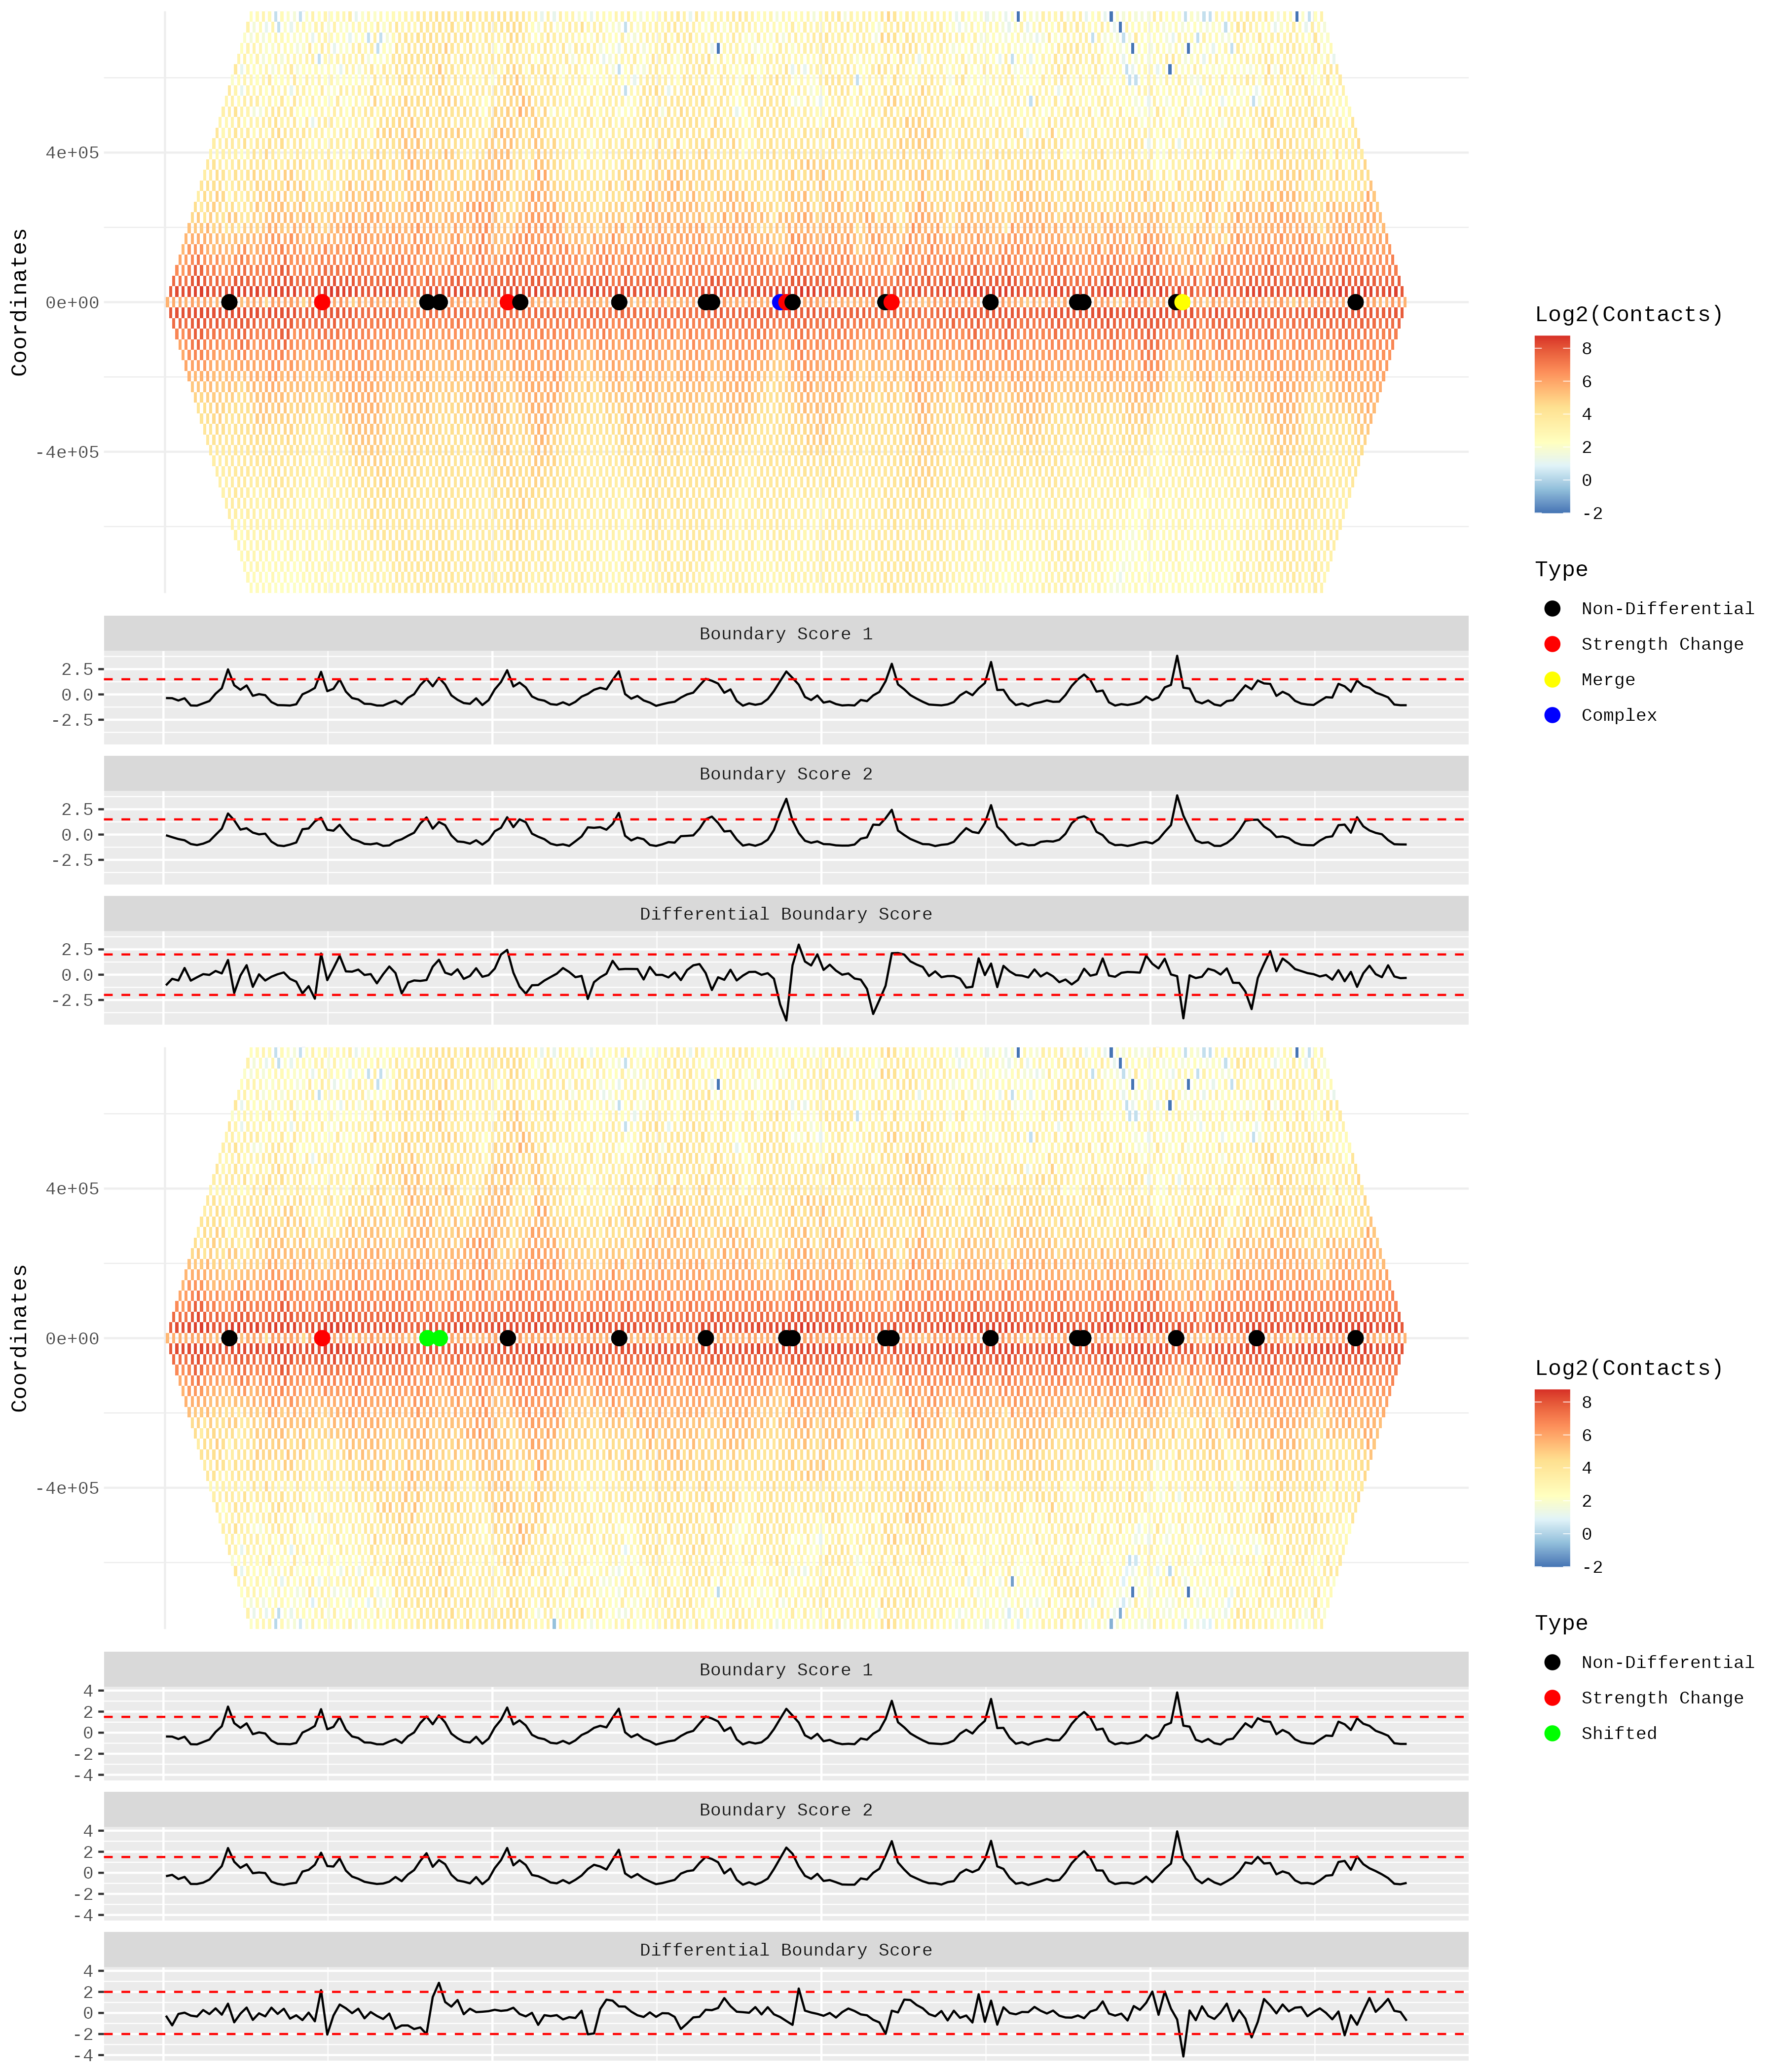

All outputs saved in:
/content/drive/MyDrive/HiC_Dataset_Explore/runs/dataset_1/chr16/run_1_8cell.cool_chr16_2026/exp3D_tadcompare_20260704_011424


In [ ]:
summary_path = (
    RESULTS_DIR
    / "tadcompare_summary_all_methods.csv"
)

comparison_path = (
    RESULTS_DIR
    / "tadcompare_baseline_vs_ugrhic.csv"
)

representative_path = (
    RESULTS_DIR
    / "representative_region.csv"
)

summary_df = pd.read_csv(summary_path)
comparison_df = pd.read_csv(comparison_path)
representative_df = pd.read_csv(representative_path)

method_means_df = (
    summary_df
    .groupby(
        ["method", "method_key"],
        as_index=False,
    )
    [
        [
            "differential_boundary_fraction",
            "boundary_score_correlation",
            "mean_absolute_gap_score",
        ]
    ]
    .mean()
)

method_means_path = (
    RESULTS_DIR
    / "tadcompare_method_means.csv"
)

method_means_df.to_csv(
    method_means_path,
    index=False,
)

interpretation_rows = []

for _, row in comparison_df.iterrows():
    improved_indicators = sum([
        row["differential_fraction_reduction"] > 0,
        row["boundary_correlation_gain"] > 0,
        row["mean_absolute_gap_reduction"] > 0,
    ])

    if improved_indicators == 3:
        conclusion = (
            "UGR-HiC improved all three "
            "TADCompare indicators."
        )
    elif improved_indicators == 2:
        conclusion = (
            "UGR-HiC improved two of the three "
            "TADCompare indicators."
        )
    elif improved_indicators == 1:
        conclusion = (
            "UGR-HiC improved one indicator; "
            "the result is mixed."
        )
    else:
        conclusion = (
            "UGR-HiC did not improve the three "
            "reported indicators."
        )

    interpretation_rows.append({
        "Forecast horizon": row["forecast_label"],
        "Matched stage": row["matched_stage"],
        "Improved indicators": improved_indicators,
        "Conclusion": conclusion,
    })

interpretation_df = pd.DataFrame(
    interpretation_rows
)

interpretation_df.to_csv(
    RESULTS_DIR / "tadcompare_interpretation.csv",
    index=False,
)

print("All-method summary")
display(
    summary_df[
        [
            "forecast_label",
            "matched_stage",
            "method",
            "differential_boundary_fraction",
            "boundary_score_correlation",
            "mean_absolute_gap_score",
        ]
    ].round(6)
)

print("Mean across three horizons")
display(
    method_means_df.round(6)
)

print("Baseline versus UGR-HiC")
display(
    comparison_df.round(6)
)

print("Conservative interpretation")
display(
    interpretation_df
)

print("Representative region")
display(
    representative_df
)

display(
    Image(
        filename=str(
            FIGURES_DIR
            / "representative_TADCompare.png"
        )
    )
)

print("All outputs saved in:")
print(OUTPUT_DIR)